# MLP para previsão de crimes de trânsito no estado de São Paulo

**Dataset:** `SPDadosCriminais_FINAL.csv` (813.622 B.O.s, 2022–2025, 7 tipos de crime).

**REGISTRO** = aglomerado de B.O.s com chave
`(célula geográfica, dia da semana, faixa de horário)`:

| componente | regra |
|---|---|
| célula | `lat`/`lon` arredondados para uma grade de `0,04°` ≈ 4,4 km × 4,1 km |
| dia da semana | extraído de `DATA_OCORRENCIA_BO` (0 = segunda) |
| faixa de horário | 4 faixas de 6 h a partir de `HORA_OCORRENCIA_BO` (madrugada/manhã/tarde/noite) |

Cada registro traz **número total de crimes** e **proporção (%) de cada tipo de crime**
(`NATUREZA_APURADA`), calculados nas duas janelas temporais:

* **JANELA A (2022–2023)** → gera as *features* (perfil temporal + histórico + localização);
* **JANELA B (2024–2025)** → gera os *alvos* (total + proporções) que a MLP deve prever.

O corte temporal separa features e alvos: nada da janela B vaza para as entradas do modelo.

## Configuração

In [3]:
CAMINHO_CSV = "SPDadosCriminais_FINAL.csv"

GRADE_GRAUS = 0.04  # lado da célula em graus (~4,4 km lat / 4,1 km lon em -23°)

JANELA_FEAT = (2022, 2023)  # janela que fornece features/histórico
JANELA_ALVO = (2024, 2025)  # janela dos alvos (total + proporções)

EXCLUIR_HORA_INCERTA = False   # True: descarta os 14.774 B.O.s com DESC_PERIODO == 'EM HORA INCERTA'
INCLUIR_MIX_HISTORICO = True   # True: usa as proporções da janela A como features de histórico

N_ITER_BUSCA = 30   # avaliações do RandomizedSearchCV
N_FOLDS = 5
N_JOBS = -1         # processos paralelos; cada um com 1 thread de BLAS
SEED = 42

CARREGAR_MODELO = True    # True: exige mlp_melhor.joblib e pula a busca; False: treina do zero
REUSAR_REGISTROS = True   # True: se registros.csv existir, pula a leitura do CSV de 173 MB e a agregação
RODAR_IMPORTANCIA = True  # False: pula permutation_importance e o gráfico de importância

ARQ_REGISTROS = "registros.csv"
ARQ_MODELO = "mlp_melhor.joblib"
ARQ_BUSCA = "busca_hiperparametros.csv"

# chave do REGISTRO: (célula geográfica, dia da semana, faixa de horário)
CHAVE = ["cel_lat", "cel_lon", "dia_semana", "faixa"]

## Dependências

In [4]:
import re
import time
import unicodedata
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import parallel_config
from scipy.stats import loguniform
from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True

## Construção dos registros

escartamos: datas ilegíveis, hora ausente/inválida e coordenadas fora da faixa do
estado de SP (o CSV contém `NaN`, `0.0` e valores-corruptos como `-2.3e16`).
As funções abaixo só são *definidas* aqui — quem decide reusar o cache ou reconstruir
do CSV bruto é a célula da seção 3.

In [5]:
def slug(texto: str) -> str:
    texto = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return re.sub(r"[^A-Za-z0-9]+", "_", texto).strip("_").upper()


def agregar(dados: pd.DataFrame, tipos: list) -> pd.DataFrame:
    col_tipo = {t: f"prop_{slug(t)}" for t in tipos}
    g = dados.groupby(CHAVE, sort=True)
    out = pd.DataFrame(
        {
            "n_bos": g.size(),
            "n_dias": g["data"].nunique(),
            "n_meses": g["mes"].nunique(),
        }
    )

    mix = (
        g["tipo"]
        .value_counts(normalize=True)
        .unstack(fill_value=0.0)
        .mul(100.0)
        .reindex(columns=tipos, fill_value=0.0)
        .rename(columns=col_tipo)
    )
    out = out.join(mix)

    circ = (
        dados.assign(
            _sh=np.sin(dados["hora_rad"]),
            _ch=np.cos(dados["hora_rad"]),
            _sm=np.sin(dados["mes_rad"]),
            _cm=np.cos(dados["mes_rad"]),
        )
        .groupby(CHAVE, sort=True)[["_sh", "_ch", "_sm", "_cm"]]
        .mean()
    )
    out["hora_sin"] = circ["_sh"]
    out["hora_cos"] = circ["_ch"]
    out["mes_sin"] = circ["_sm"]
    out["mes_cos"] = circ["_cm"]
    out["hora_media"] = (np.arctan2(circ["_sh"], circ["_ch"]) % (2 * np.pi)) / (2 * np.pi) * 24
    out["mes_medio"] = (np.arctan2(circ["_sm"], circ["_cm"]) % (2 * np.pi)) / (2 * np.pi) * 12
    return out.reset_index()


def construir_registros() -> pd.DataFrame:
    """Lê o CSV bruto, aplica a chave (célula, dia da semana, faixa) e agrega as janelas A/B."""
    COLS = [
        "DATA_OCORRENCIA_BO",
        "HORA_OCORRENCIA_BO",
        "DESC_PERIODO",
        "LATITUDE",
        "LONGITUDE",
        "NATUREZA_APURADA",
    ]

    bruto = pd.read_csv(CAMINHO_CSV, usecols=COLS, low_memory=False)
    print(f"linhas brutas: {len(bruto):,}")

    df = bruto.copy()
    df["data"] = pd.to_datetime(df["DATA_OCORRENCIA_BO"], errors="coerce")

    # a coluna de hora aparece em 3 formatos: 'HH:MM:SS', 'YYYY-MM-DD HH:MM:SS' e 'HH:MM:SS.f'
    _extraida = df["HORA_OCORRENCIA_BO"].astype(str).str.extract(r"(\d{1,2}):(\d{2})")
    df["hora"] = pd.to_numeric(_extraida[0], errors="coerce")

    df["lat"] = pd.to_numeric(df["LATITUDE"], errors="coerce")
    df["lon"] = pd.to_numeric(df["LONGITUDE"], errors="coerce")
    df["tipo"] = df["NATUREZA_APURADA"].astype(str).str.strip()

    mascara = (
        df["data"].notna()
        & df["hora"].between(0, 23)
        & df["lat"].between(-25.6, -19.4)
        & df["lon"].between(-53.6, -44.0)
        & df["tipo"].notna()
        & df["tipo"].ne("nan")
    )
    if EXCLUIR_HORA_INCERTA:
        mascara &= df["DESC_PERIODO"].ne("EM HORA INCERTA")

    df = df.loc[mascara].copy()
    print(f"linhas válidas: {len(df):,}  (descartadas: {len(bruto) - len(df):,})")

    NOMES_DIA = ["segunda", "terca", "quarta", "quinta", "sexta", "sabado", "domingo"]
    NOMES_FAIXA = ["madrugada (00-06h)", "manha (06-12h)", "tarde (12-18h)", "noite (18-24h)"]

    df["ano"] = df["data"].dt.year
    df["mes"] = df["data"].dt.month
    df["dia_semana"] = df["data"].dt.day_of_week.map(dict(enumerate(NOMES_DIA)))
    df["faixa"] = (df["hora"] // 6).astype(int).map(dict(enumerate(NOMES_FAIXA)))

    df["cel_lat"] = (df["lat"] / GRADE_GRAUS).round() * GRADE_GRAUS
    df["cel_lon"] = (df["lon"] / GRADE_GRAUS).round() * GRADE_GRAUS
    df[["cel_lat", "cel_lon"]] = df[["cel_lat", "cel_lon"]].round(6)

    df["hora_rad"] = 2 * np.pi * df["hora"] / 24
    df["mes_rad"] = 2 * np.pi * (df["mes"] - 0.5) / 12

    tipos = df["tipo"].value_counts().index.tolist()
    print(f"células: {df.groupby(['cel_lat', 'cel_lon']).ngroups:,}")
    print(f"tipos de crime ({len(tipos)}):")
    for t in tipos:
        print(f"  - {t}")

    reg_A = agregar(df[df["ano"].between(*JANELA_FEAT)], tipos)
    reg_B = agregar(df[df["ano"].between(*JANELA_ALVO)], tipos)
    registros = reg_A.merge(reg_B, on=CHAVE, how="inner", suffixes=("_A", "_B"))

    print(f"registros (chaves) janela A: {len(reg_A):,}")
    print(f"registros (chaves) janela B: {len(reg_B):,}")
    print(f"REGISTROS usados (A ∩ B):    {len(registros):,}")
    return registros

## Registros do cache ou reconstrução

* `REUSAR_REGISTROS = True` **e** `registros.csv` presente → lê o cache e **pula**
a leitura do CSV de 173 MB + a agregação (segundos em vez de minutos no Colab);
* caso contrário reconstrói do CSV bruto e regrava o cache.

Cada linha é um registro `(célula, dia da semana, faixa)` com total de crimes e
proporção (%) de cada tipo nas duas janelas.

In [6]:
if REUSAR_REGISTROS and Path(ARQ_REGISTROS).exists():
    registros = pd.read_csv(ARQ_REGISTROS)
    print(
        f"REGISTROS lidos do cache {Path(ARQ_REGISTROS).resolve()}\n"
        f"  {registros.shape[0]:,} linhas × {registros.shape[1]} colunas"
    )
else:
    if REUSAR_REGISTROS:
        print(f"cache {ARQ_REGISTROS} não encontrado — reconstruindo do CSV bruto")
    registros = construir_registros()
    registros.to_csv(ARQ_REGISTROS, index=False)
    print(
        f"gravado: {ARQ_REGISTROS}  ({registros.shape[0]:,} linhas × {registros.shape[1]} colunas)"
    )

registros.head()

REGISTROS lidos do cache /content/registros.csv
  24,354 linhas × 36 colunas


,cel_lat,cel_lon,dia_semana,faixa,n_bos_A,n_dias_A,n_meses_A,prop_FURTO_DE_VEICULO_A,prop_LESAO_CORPORAL_CULPOSA_POR_ACIDENTE_DE_TRANSITO_A,prop_ROUBO_DE_VEICULO_A,prop_ROUBO_DE_CARGA_A,prop_HOMICIDIO_CULPOSO_POR_ACIDENTE_DE_TRANSITO_A,prop_FURTO_DE_CARGA_A,prop_HOMICIDIO_DOLOSO_POR_ACIDENTE_DE_TRANSITO_A,hora_sin_A,hora_cos_A,mes_sin_A,mes_cos_A,hora_media_A,mes_medio_A,n_bos_B,n_dias_B,n_meses_B,prop_FURTO_DE_VEICULO_B,prop_LESAO_CORPORAL_CULPOSA_POR_ACIDENTE_DE_TRANSITO_B,prop_ROUBO_DE_VEICULO_B,prop_ROUBO_DE_CARGA_B,prop_HOMICIDIO_CULPOSO_POR_ACIDENTE_DE_TRANSITO_B,prop_FURTO_DE_CARGA_B,prop_HOMICIDIO_DOLOSO_POR_ACIDENTE_DE_TRANSITO_B,hora_sin_B,hora_cos_B,mes_sin_B,mes_cos_B,hora_media_B,mes_medio_B
0,-25.00,-47.92,domingo,manha (06-12h),1,1,1,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.866025,-0.500000,0.965926,2.588190e-01,8.0,2.5,1,1,1,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.258819,-9.659258e-01,-7.071068e-01,0.707107,11.0,10.5
1,-25.00,-47.92,sabado,manha (06-12h),1,1,1,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.965926,-0.258819,0.707107,-7.071068e-01,7.0,4.5,2,2,2,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.482963,-8.365163e-01,-1.110223e-16,0.707107,10.0,12.0
2,-25.00,-47.92,sabado,noite (18-24h),1,1,1,0.0,100.0,0.0,0.0,0.0,0.0,0.0,-0.866025,0.500000,-0.965926,-2.588190e-01,20.0,8.5,2,2,2,0.0,100.0,0.0,0.0,0.0,0.0,0.0,-0.750000,4.330127e-01,8.365163e-01,-0.224144,20.0,3.5
3,-25.00,-47.92,terca,noite (18-24h),2,2,2,0.0,100.0,0.0,0.0,0.0,0.0,0.0,-0.786566,0.603553,-0.707107,-2.775558e-16,20.5,9.0,1,1,1,0.0,100.0,0.0,0.0,0.0,0.0,0.0,-1.000000,-1.836970e-16,9.659258e-01,0.258819,18.0,2.5
4,-24.96,-48.44,quarta,noite (18-24h),2,2,2,0.0,0.0,50.0,0.0,0.0,50.0,0.0,-0.629410,0.482963,0.224144,8.365163e-01,20.5,0.5,1,1,1,0.0,0.0,100.0,0.0,0.0,0.0,0.0,-0.258819,9.659258e-01,9.659258e-01,-0.258819,23.0,3.5


## Matriz de features

**X — janela A (2022–2023)**

* *localização*: `cel_lat`, `cel_lon`;
* *temporal*: `dia_semana`, `faixa` (one-hot) + seno/cosseno de hora e mês;
* *histórico*: total de B.O.s, total em `log1p`, dias/meses distintos e — se
`INCLUIR_MIX_HISTORICO` — a proporção histórica de cada tipo de crime.

**y — janela B (2024–2025)**: `n_bos_B` (total) + 7 proporções (%).

In [7]:
registros["log_n_bos_A"] = np.log1p(registros["n_bos_A"])

MIX_A = [c for c in registros.columns if c.startswith("prop_") and c.endswith("_A")]
MIX_B = [c for c in registros.columns if c.startswith("prop_") and c.endswith("_B")]

CAT = ["dia_semana", "faixa"]
NUM = [
    "cel_lat",
    "cel_lon",
    "hora_sin_A",
    "hora_cos_A",
    "mes_sin_A",
    "mes_cos_A",
    "n_bos_A",
    "log_n_bos_A",
    "n_dias_A",
    "n_meses_A",
] + (MIX_A if INCLUIR_MIX_HISTORICO else [])

ALVOS = ["n_bos_B"] + MIX_B

X = registros[CAT + NUM].copy()
y = registros[ALVOS].to_numpy(dtype=float)

print(f"X: {X.shape[0]:,} registros × {X.shape[1]} features  ({len(CAT)} categóricas + {len(NUM)} numéricas)")
print(f"y: {y.shape[1]} alvos -> {ALVOS[0]} (contagem) + {len(MIX_B)} proporções")


def y_para_treino(y: np.ndarray) -> np.ndarray:
    """total -> log1p | proporções -> fração 0..1 (soma 1)."""
    yt = np.array(y, dtype=float, copy=True)
    yt[:, 0] = np.log1p(yt[:, 0])
    yt[:, 1:] = yt[:, 1:] / 100.0
    return yt


def y_original(yt: np.ndarray) -> np.ndarray:
    y = np.array(yt, dtype=float, copy=True)
    y[:, 0] = np.expm1(y[:, 0])
    y[:, 1:] = y[:, 1:] * 100.0
    return y


def normalizar_props(p: np.ndarray) -> np.ndarray:
    """corta negativos e re-normaliza cada linha para somar 100%."""
    p = np.clip(p, 0.0, None)
    soma = p.sum(axis=1, keepdims=True)
    return np.divide(p * 100.0, soma, out=np.zeros_like(p), where=soma > 0)


y_treino = y_para_treino(y)

X: 24,354 registros × 19 features  (2 categóricas + 17 numéricas)
y: 8 alvos -> n_bos_B (contagem) + 7 proporções


## Pré-processamento e MLP

In [8]:
pre = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
        ("num", StandardScaler(), NUM),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

mlp = MLPRegressor(
    solver="adam",
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=25,
    max_iter=600,
    random_state=SEED,
)

pipe = Pipeline([("pre", pre), ("mlp", mlp)])
pipe

Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['dia_semana', 'faixa']),
                                                 ('num', StandardScaler(),
                                                  ['cel_lat', 'cel_lon',
                                                   'hora_sin_A', 'hora_cos_A',
                                                   'mes_sin_A', 'mes_cos_A',
                                                   'n_bos_A', 'log_n_bos_A',
                                                   'n_dias_A', 'n_meses_A',
                                                   'prop_FURTO_DE_VEICULO_A',
                                                   'prop_LESAO_CORPORAL_CULPOSA_POR_ACIDENTE_DE_TRANSITO_A',
                                                   'prop_ROUBO_DE_VEICULO_A',
                                                   'prop_ROUBO_DE_CARGA_A',
                                                   'prop_HOMICIDIO_CULPOSO_POR_ACIDENTE_DE_TRANSITO_A',
                                                   'prop_FURTO_DE_CARGA_A',
                                                   'prop_HOMICIDIO_DOLOSO_POR_ACIDENTE_DE_TRANSITO_A'])],
                                   verbose_feature_names_out=False)),
                ('mlp',
                 MLPRegressor(early_stopping=True, max_iter=600,
                              n_iter_no_change=25, random_state=42,
                              validation_fraction=0.15))])

## 7. Busca dos melhores hiperparâmetros (`RandomizedSearchCV`)

Otimiza o **MSE conjunto** dos 8 alvos já transformados (total em `log1p`,
proporções como fração 0..1) — assim contagem e mix entram na mesma ordem de grandeza.
A validação cruzada (5 folds embaralhados) acontece **apenas** dentro da janela A→B;
a janela B nunca aparece no treino, portanto a avaliação final é honesta.

* Com `CARREGAR_MODELO = True` o caminho absoluto do modelo é impresso e a busca é
pulada; se o arquivo **não existir** o script aborta com `FileNotFoundError`
(em vez de treinar 40+ min sem você perceber).
* `CARREGAR_MODELO = False` força a reexecução da busca.
* Antes de usar o modelo carregado, as features atuais são comparadas com as do
modelo salvo (pegadinha típica: mudar `INCLUIR_MIX_HISTORICO`).
#
> Com `N_ITER_BUSCA = 30` a busca leva algo entre 20 e 40 min (150 ajustes de rede) —
> num Colab free (2 vCPU) pode passar de 1 h. Use um `N_ITER_BUSCA` menor lá.

In [9]:
espaco = {
    "mlp__hidden_layer_sizes": [
        (32,),
        (64,),
        (128,),
        (64, 32),
        (128, 64),
        (128, 64, 32),
        (256, 128),
        (256, 128, 64),
    ],
    "mlp__activation": ["relu", "tanh"],
    "mlp__alpha": loguniform(1e-6, 1e-2),
    "mlp__learning_rate_init": loguniform(1e-4, 1e-2),
    "mlp__learning_rate": ["constant", "adaptive"],
    "mlp__batch_size": [64, 128, 256, 512],
    "mlp__max_iter": [400, 600, 800],
}

CAMINHO_MODELO = Path(ARQ_MODELO).resolve()

if CARREGAR_MODELO:
    if not CAMINHO_MODELO.exists():
        raise FileNotFoundError(
            "CARREGAR_MODELO = True, mas o modelo treinado não foi encontrado.\n"
            f"  caminho testado: {CAMINHO_MODELO}\n"
            f"  Coloque '{ARQ_MODELO}' nessa pasta (a mesma onde está o CSV) ou mude "
            "ARQ_MODELO para o caminho completo.\n"
            "  Para treinar do zero, defina CARREGAR_MODELO = False."
        )

    print(f"MODELO: carregando de {CAMINHO_MODELO} (busca de hiperparâmetros pulada)")
    modelo = joblib.load(CAMINHO_MODELO)
    busca = None
    resumo = pd.DataFrame()

    esperadas = list(X.columns)
    treinadas = list(getattr(modelo.named_steps["pre"], "feature_names_in_", esperadas))
    if treinadas != esperadas:
        raise ValueError(
            "As features atuais não batem com as do modelo salvo.\n"
            f"  modelo: {treinadas}\n"
            f"  atual : {esperadas}\n"
            "Provável causa: INCLUIR_MIX_HISTORICO (ou as janelas de tempo) mudou depois "
            "do treino. Rode com CARREGAR_MODELO = False para retreinar."
        )

    p = modelo.named_steps["mlp"].get_params()
    print("hiperparâmetros do modelo carregado:")
    for k in [
        "hidden_layer_sizes",
        "activation",
        "alpha",
        "learning_rate_init",
        "learning_rate",
        "batch_size",
        "max_iter",
    ]:
        print(f"  mlp__{k}: {p[k]}")
else:
    print(f"MODELO: treinando do zero (CARREGAR_MODELO = False) -> {CAMINHO_MODELO}")

    busca = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=espaco,
        n_iter=N_ITER_BUSCA,
        scoring="neg_mean_squared_error",
        cv=KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED),
        n_jobs=N_JOBS,
        random_state=SEED,
        refit=True,
        return_train_score=True,
        verbose=1,
    )

    t0 = time.perf_counter()
    with parallel_config(backend="loky", n_jobs=N_JOBS, inner_max_num_threads=1):
        busca.fit(X, y_treino)
    tempo = time.perf_counter() - t0

    print(f"\nconcluído em {tempo/60:.1f} min ({busca.n_splits_} folds × {N_ITER_BUSCA} avaliações)")
    print("melhores hiperparâmetros:")
    for k, v in busca.best_params_.items():
        print(f"  {k}: {v}")
    print(f"melhor MSE (y transformado): {-busca.best_score_:.6f}")

    resumo = pd.DataFrame(busca.cv_results_)
    cols = ["rank_test_score", "mean_test_score", "std_test_score", "mean_fit_time", "params"]
    resumo = resumo.sort_values("rank_test_score")[cols].reset_index(drop=True)
    resumo.to_csv(ARQ_BUSCA, index=False)
    print(f"resultados da busca gravados em {ARQ_BUSCA}")
    print(resumo.head(10).to_string(index=False))

    modelo = busca.best_estimator_

MODELO: carregando de /content/mlp_melhor.joblib (busca de hiperparâmetros pulada)
hiperparâmetros do modelo carregado:
  mlp__hidden_layer_sizes: (64, 32)
  mlp__activation: tanh
  mlp__alpha: 1.6813042706040678e-06
  mlp__learning_rate_init: 0.00026587543983272726
  mlp__learning_rate: adaptive
  mlp__batch_size: 512
  mlp__max_iter: 400


## Avaliação na janela de teste (2024-2025)

In [10]:
pred = y_original(modelo.predict(X))
pred[:, 0] = np.clip(pred[:, 0], 0.0, None)
pred[:, 1:] = normalizar_props(pred[:, 1:])


def metricas_total(real: np.ndarray, prev: np.ndarray) -> dict:
    err = prev - real
    return {
        "RMSE": float(np.sqrt(mean_squared_error(real, prev))),
        "MAE": float(mean_absolute_error(real, prev)),
        "R2": float(r2_score(real, prev)),
        "WAPE_%": float(100 * np.abs(err).sum() / np.abs(real).sum()),
    }


def metricas_props(real: np.ndarray, prev: np.ndarray) -> pd.Series:
    return pd.Series(
        np.abs(prev - real).mean(axis=0),
        index=[c.replace("prop_", "").replace("_B", "") for c in ALVOS[1:]],
        name="MAE_pp",
    )


mae_props_ml = metricas_props(y[:, 1:], pred[:, 1:])

# --- baselines ingênuos -------------------------------------------------
base_media_total = np.full(len(y), y[:, 0].mean())
base_persist_total = registros["n_bos_A"].to_numpy(dtype=float)

mix_hist = registros[MIX_A].to_numpy(dtype=float)
mix_medio = np.tile(y[:, 1:].mean(axis=0), (len(y), 1))


def linha_comparativo(modelo: str, total_prev: np.ndarray, props_prev: np.ndarray) -> dict:
    m = metricas_total(y[:, 0], total_prev)
    return {
        "modelo": modelo,
        "RMSE_total": m["RMSE"],
        "MAE_total": m["MAE"],
        "R2_total": m["R2"],
        "WAPE_total_%": m["WAPE_%"],
        "MAE_mix_pp": float(np.abs(props_prev - y[:, 1:]).mean()),
    }


comparativo = pd.DataFrame(
    [
        linha_comparativo("MLP (busca de hiperparâmetros)", pred[:, 0], pred[:, 1:]),
        linha_comparativo("Baseline: constante (média global)", base_media_total, mix_medio),
        linha_comparativo(
            "Baseline: persistência (n_A) / mix histórico", base_persist_total, mix_hist
        ),
    ]
)

print("=== Total de crimes (janela 2024-2025) ===")
print(comparativo.to_string(index=False))
print("\n=== Mix de crimes: MAE por tipo (percentuais pontuais) ===")
print(mae_props_ml.sort_values(ascending=False).to_string())

=== Total de crimes (janela 2024-2025) ===
                                      modelo  RMSE_total  MAE_total  R2_total  WAPE_total_%  MAE_mix_pp
              MLP (busca de hiperparâmetros)    6.728423   3.461957  0.938139     25.850595    9.202631
          Baseline: constante (média global)   27.052232  14.759426  0.000000    110.209340   12.380378
Baseline: persistência (n_A) / mix histórico    8.161130   3.962511  0.908989     29.588261    9.967410

=== Mix de crimes: MAE por tipo (percentuais pontuais) ===
LESAO_CORPORAL_CULPOSA_POR_ACIDENTE_DE_TRANSITO    21.767649
FURTO_DE_VEICULO                                   18.560351
ROUBO_DE_VEICULO                                   11.927069
HOMICIDIO_CULPOSO_POR_ACIDENTE_DE_TRANSITO          7.303200
ROUBO_DE_CARGA                                      3.710448
FURTO_DE_CARGA                                      1.025623
HOMICIDIO_DOLOSO_POR_ACIDENTE_DE_TRANSITO           0.124076


## Qual feature mais ajuda a MLP?
Pulável com `RODAR_IMPORTANCIA = False`

In [11]:
if RODAR_IMPORTANCIA:
    with parallel_config(backend="loky", n_jobs=N_JOBS, inner_max_num_threads=1):
        imp = permutation_importance(
            modelo,
            X,
            y_treino,
            n_repeats=8,
            random_state=SEED,
            n_jobs=N_JOBS,
            scoring="neg_mean_squared_error",
        )

    ordem = np.argsort(imp.importances_mean)[::-1][:16]
    imp_df = pd.DataFrame(
        {
            "feature": X.columns[ordem],
            "importancia": imp.importances_mean[ordem],
            "std": imp.importances_std[ordem],
        }
    )
else:
    imp_df = pd.DataFrame(columns=["feature", "importancia", "std"])
    print("RODAR_IMPORTANCIA = False — permutation_importance pulada")

if not imp_df.empty:
    print(imp_df.to_string(index=False))


                                               feature  importancia      std
                                               n_bos_A     0.091283 0.000912
                                              n_dias_A     0.022417 0.000229
prop_LESAO_CORPORAL_CULPOSA_POR_ACIDENTE_DE_TRANSITO_A     0.016775 0.000127
                                           log_n_bos_A     0.016673 0.000187
                               prop_FURTO_DE_VEICULO_A     0.011423 0.000161
                               prop_ROUBO_DE_VEICULO_A     0.009969 0.000161
                                                 faixa     0.005675 0.000118
                                               cel_lon     0.004858 0.000078
                                 prop_ROUBO_DE_CARGA_A     0.003136 0.000106
     prop_HOMICIDIO_CULPOSO_POR_ACIDENTE_DE_TRANSITO_A     0.002481 0.000070
                                               cel_lat     0.002226 0.000038
                                             n_meses_A     0.001295 0.000036

## Gráficos

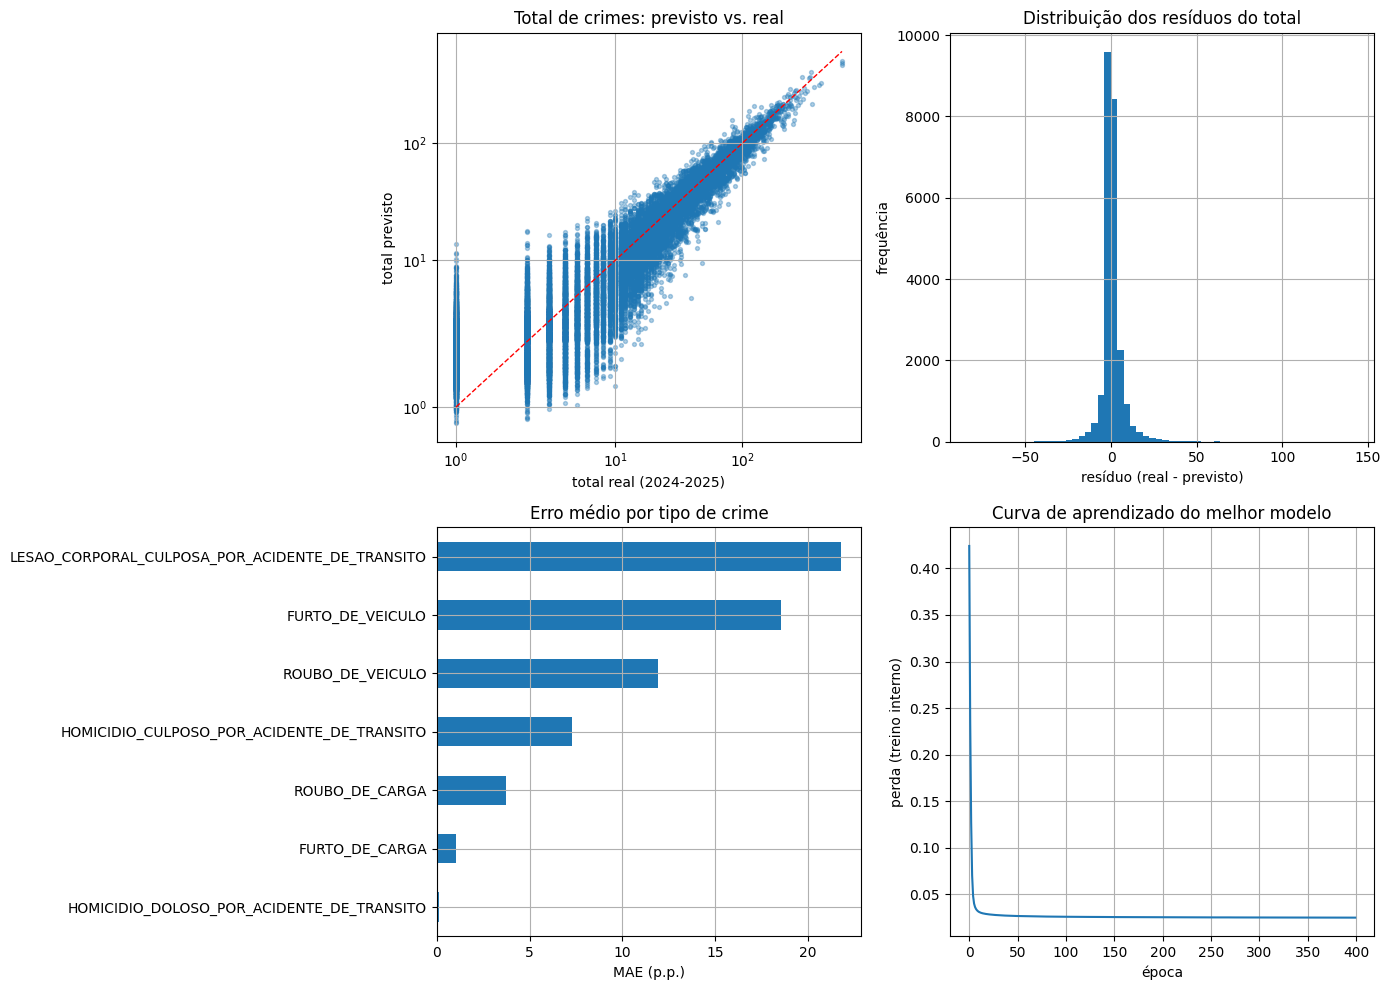

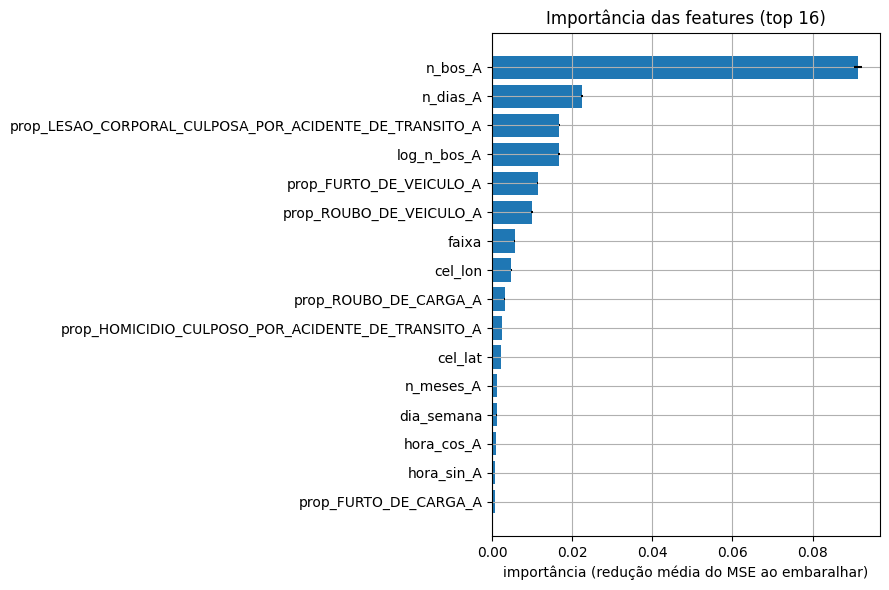

In [12]:
fig, eixos = plt.subplots(2, 2, figsize=(14, 10))

ax = eixos[0, 0]
ax.scatter(y[:, 0], pred[:, 0], s=8, alpha=0.35)
lim = [max(1, y[:, 0].min()), max(y[:, 0].max(), pred[:, 0].max())]
ax.plot(lim, lim, "r--", lw=1)
ax.set_xscale("symlog")
ax.set_yscale("symlog")
ax.set_xlabel("total real (2024-2025)")
ax.set_ylabel("total previsto")
ax.set_title("Total de crimes: previsto vs. real")

ax = eixos[0, 1]
ax.hist(y[:, 0] - pred[:, 0], bins=60)
ax.set_xlabel("resíduo (real - previsto)")
ax.set_ylabel("frequência")
ax.set_title("Distribuição dos resíduos do total")

ax = eixos[1, 0]
mae_props_ml.sort_values().plot.barh(ax=ax)
ax.set_xlabel("MAE (p.p.)")
ax.set_title("Erro médio por tipo de crime")

ax = eixos[1, 1]
curva = modelo.named_steps["mlp"].loss_curve_
ax.plot(curva)
ax.set_xlabel("época")
ax.set_ylabel("perda (treino interno)")
ax.set_title("Curva de aprendizado do melhor modelo")

plt.tight_layout()
plt.show()

# %%
if RODAR_IMPORTANCIA:
    fig, ax = plt.subplots(figsize=(9, 6))
    imp_ord = imp_df.iloc[::-1]
    ax.barh(imp_ord["feature"], imp_ord["importancia"], xerr=imp_ord["std"])
    ax.set_xlabel("importância (redução média do MSE ao embaralhar)")
    ax.set_title("Importância das features (top 16)")
    plt.tight_layout()
    plt.show()
else:
    print("gráfico de importância pulado (RODAR_IMPORTANCIA = False)")


## Salvamento

Artefatos: `registros.csv` (agregações), `busca_hiperparametros.csv` (ranking da
busca, só quando ela roda) e `mlp_melhor.joblib` (pipeline pré-processamento + MLP).
Na próxima execução `CARREGAR_MODELO = True` reaproveita o `.joblib` salvo aqui.

In [13]:
joblib.dump(modelo, ARQ_MODELO)
print(f"modelo       -> {ARQ_MODELO}")
print(f"registros    -> {ARQ_REGISTROS}")
if busca is not None:
    print(f"hiperparâms. -> {ARQ_BUSCA}")

amostra = registros.assign(
    total_real=y[:, 0], total_previsto=pred[:, 0], erro=pred[:, 0] - y[:, 0]
)[CHAVE + ["n_bos_A", "total_real", "total_previsto", "erro"] + MIX_B[:3]]
amostra.sort_values("n_bos_A", ascending=False).head(10)

modelo       -> mlp_melhor.joblib
registros    -> registros.csv


,cel_lat,cel_lon,dia_semana,faixa,n_bos_A,total_real,total_previsto,erro,prop_FURTO_DE_VEICULO_B,prop_LESAO_CORPORAL_CULPOSA_POR_ACIDENTE_DE_TRANSITO_B,prop_ROUBO_DE_VEICULO_B
5318,-23.56,-46.56,quinta,noite (18-24h),517,605.0,503.177987,-101.822013,91.074380,4.462810,4.297521
5314,-23.56,-46.56,quarta,noite (18-24h),496,607.0,488.042181,-118.957819,92.257002,5.107084,2.635914
5334,-23.56,-46.56,terca,noite (18-24h),456,604.0,461.413418,-142.586582,91.887417,4.470199,3.642384
5315,-23.56,-46.56,quarta,tarde (12-18h),449,348.0,408.453181,60.453181,81.896552,15.229885,2.586207
5319,-23.56,-46.56,quinta,tarde (12-18h),404,342.0,365.256121,23.256121,83.040936,12.280702,2.923977
5335,-23.56,-46.56,terca,tarde (12-18h),390,336.0,361.706759,25.706759,84.821429,11.607143,2.976190
5330,-23.56,-46.56,sexta,noite (18-24h),389,294.0,370.021133,76.021133,77.210884,12.244898,10.204082
5317,-23.56,-46.56,quinta,manha (06-12h),349,230.0,265.147062,35.147062,86.086957,11.739130,1.304348
5333,-23.56,-46.56,terca,manha (06-12h),346,255.0,270.085434,15.085434,83.137255,14.509804,0.392157
5331,-23.56,-46.56,sexta,tarde (12-18h),339,238.0,290.065176,52.065176,78.991597,15.966387,3.361345
